# Proyek Klasifikasi Gambar: Klasifikasi Hewan
- **Nama:** Hartanto Dewantoro
- **Email:** hartantodewantoro1999@gmail.com
- **ID Dicoding:** hartadewan

## Import Semua Library

In [5]:
!pip install split-folders --quiet

In [6]:
import os
import glob
import random
import shutil
import pathlib
import splitfolders
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.callbacks import (EarlyStopping, ReduceLROnPlateau,
                                        ModelCheckpoint, Callback)


# ---- Reproducibility ----
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow :", tf.__version__)
print("Keras      :", tf.keras.__version__)
print("GPU aktif  :", tf.config.list_physical_devices('GPU'))

TensorFlow : 2.20.0
Keras      : 3.13.2
GPU aktif  : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Data Preparation

In [12]:
dataset_path = kagglehub.dataset_download("alessiocorrado99/animals10")
print("Lokasi dataset:", dataset_path)

# Cari folder yang berisi sub-folder kelas ('raw-img')
kandidat = glob.glob(os.path.join(dataset_path, "**", "raw-img"), recursive=True)
SOURCE_DIR = kandidat[0] if kandidat else dataset_path
print("Direktori sumber kelas:", SOURCE_DIR)
print("Kelas tersedia (nama asli/Italia):", sorted(os.listdir(SOURCE_DIR)))

Using Colab cache for faster access to the 'animals10' dataset.
Lokasi dataset: /kaggle/input/animals10
Direktori sumber kelas: /kaggle/input/animals10/raw-img
Kelas tersedia (nama asli/Italia): ['cane', 'cavallo', 'elefante', 'farfalla', 'gallina', 'gatto', 'mucca', 'pecora', 'ragno', 'scoiattolo']


In [13]:
# =========================================================
TRANSLATE = {
    "cane": "anjing", "cavallo": "kuda", "elefante": "gajah",
    "farfalla": "kupu_kupu", "gallina": "ayam", "gatto": "kucing",
    "mucca": "sapi", "pecora": "domba", "ragno": "laba_laba",
    "scoiattolo": "tupai",
}
# Total ~14.900 gambar
SELECTED_CLASSES = ["cane", "ragno", "gallina", "farfalla"]
VALID_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".gif"}

WORK_DIR = "/content/dataset_kerja"
if os.path.exists(WORK_DIR):
    shutil.rmtree(WORK_DIR)
os.makedirs(WORK_DIR)

total_disalin, total_dilewati = 0, 0
for kelas_it in SELECTED_CLASSES:
    src = os.path.join(SOURCE_DIR, kelas_it)
    dst = os.path.join(WORK_DIR, TRANSLATE[kelas_it])
    os.makedirs(dst, exist_ok=True)
    for berkas in os.listdir(src):
        if pathlib.Path(berkas).suffix.lower() not in VALID_EXT:
            total_dilewati += 1
            continue
        try:
            with Image.open(os.path.join(src, berkas)) as im:
                im.verify()
            shutil.copy2(os.path.join(src, berkas), os.path.join(dst, berkas))
            total_disalin += 1
        except Exception:
            total_dilewati += 1

print(f"Total gambar valid disalin : {total_disalin}")
print(f"Total berkas dilewati      : {total_dilewati} (rusak / bukan gambar)")
print("Kelas final                :", sorted(os.listdir(WORK_DIR)))

Total gambar valid disalin : 14894
Total berkas dilewati      : 0 (rusak / bukan gambar)
Kelas final                : ['anjing', 'ayam', 'kupu_kupu', 'laba_laba']


Distribusi gambar per kelas:
  - anjing      : 4863
  - ayam        : 3098
  - kupu_kupu   : 2112
  - laba_laba   : 4821

Total gambar          : 14894
Jumlah resolusi unik  : 724
Contoh resolusi asli  : [(449, 640), (640, 320), (300, 270), (640, 329), (300, 279), (181, 300), (640, 576), (278, 251)]

Memenuhi: >= 10.000 gambar, >= 3 kelas, resolusi beragam.


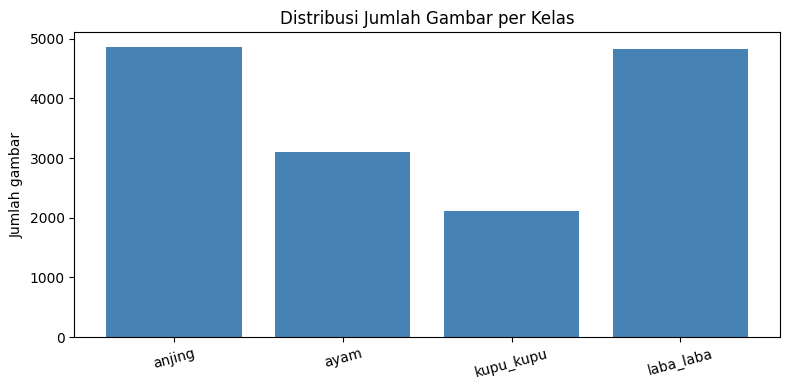

In [14]:
# =========================================================
def ringkas_dataset(direktori):
    ukuran_unik = set()
    total = 0
    distribusi = {}
    for sub in sorted(os.listdir(direktori)):
        sub_path = os.path.join(direktori, sub)
        if not os.path.isdir(sub_path):
            continue
        berkas = os.listdir(sub_path)
        distribusi[sub] = len(berkas)
        total += len(berkas)
        for f in berkas:
            with Image.open(os.path.join(sub_path, f)) as img:
                ukuran_unik.add(img.size)
    return total, distribusi, ukuran_unik

total_gambar, distribusi, ukuran_unik = ringkas_dataset(WORK_DIR)
print("Distribusi gambar per kelas:")
for k, v in distribusi.items():
    print(f"  - {k:12s}: {v}")
print(f"\nTotal gambar          : {total_gambar}")
print(f"Jumlah resolusi unik  : {len(ukuran_unik)}")
print("Contoh resolusi asli  :", list(ukuran_unik)[:8])

assert total_gambar >= 10000, "Total gambar harus >= 10.000."
assert len(distribusi) >= 3,  "Jumlah kelas harus >= 3."
assert len(ukuran_unik) > 1,  "Resolusi asli harus beragam (saran)."
print("\nMemenuhi: >= 10.000 gambar, >= 3 kelas, resolusi beragam.")

# Visualisasi distribusi kelas
plt.figure(figsize=(8, 4))
plt.bar(list(distribusi.keys()), list(distribusi.values()), color="steelblue")
plt.title("Distribusi Jumlah Gambar per Kelas")
plt.ylabel("Jumlah gambar")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

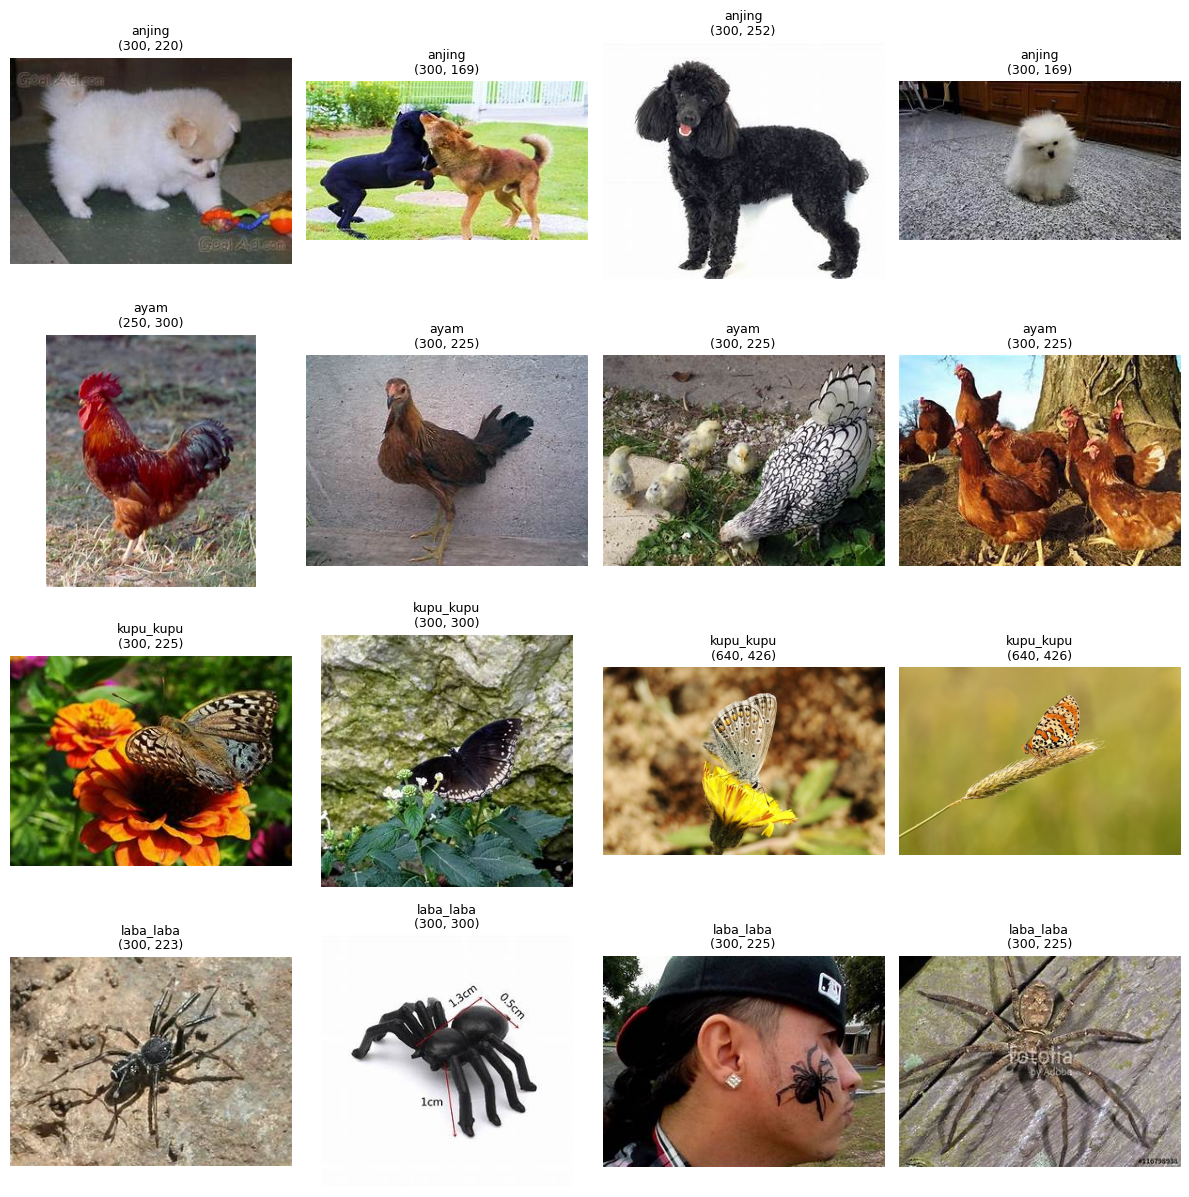

In [15]:
# =========================================================
kelas_list = sorted(os.listdir(WORK_DIR))
plt.figure(figsize=(12, 3 * len(kelas_list)))
for i, kelas in enumerate(kelas_list):
    contoh = os.listdir(os.path.join(WORK_DIR, kelas))[:4]
    for j, berkas in enumerate(contoh):
        ax = plt.subplot(len(kelas_list), 4, i * 4 + j + 1)
        img = Image.open(os.path.join(WORK_DIR, kelas, berkas))
        ax.imshow(img)
        ax.set_title(f"{kelas}\n{img.size}", fontsize=9)
        ax.axis("off")
plt.tight_layout()
plt.show()

### Data Preprocessing

#### Split Dataset

In [16]:
OUTPUT_SPLIT = "/content/dataset_split"
if os.path.exists(OUTPUT_SPLIT):
    shutil.rmtree(OUTPUT_SPLIT)

splitfolders.ratio(WORK_DIR, output=OUTPUT_SPLIT, seed=SEED, ratio=(0.8, 0.1, 0.1))
print("Struktur hasil split:", os.listdir(OUTPUT_SPLIT))

# ---- Parameter citra ----
IMG_SIZE = (160, 160)
BATCH_SIZE = 32

def muat_dataset(subset, acak):
    return tf.keras.utils.image_dataset_from_directory(
        os.path.join(OUTPUT_SPLIT, subset),
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="int",
        shuffle=acak,
        seed=SEED,
    )

train_ds = muat_dataset("train", acak=True)
val_ds   = muat_dataset("val",   acak=False)
test_ds  = muat_dataset("test",  acak=False)

class_names = train_ds.class_names
print("Label kelas (urutan indeks):", class_names)

# Data validation & test
AUTOTUNE = tf.data.AUTOTUNE
augmentasi = models.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.10),
], name="augmentasi_data")

train_ds = (train_ds
            .map(lambda x, y: (augmentasi(x, training=True), y),
                 num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))
val_ds  = val_ds.cache().prefetch(AUTOTUNE)
test_ds = test_ds.cache().prefetch(AUTOTUNE)

Copying files: 14894 files [00:02, 5952.79 files/s]


Struktur hasil split: ['test', 'train', 'val']
Found 11913 files belonging to 4 classes.
Found 1488 files belonging to 4 classes.
Found 1493 files belonging to 4 classes.
Label kelas (urutan indeks): ['anjing', 'ayam', 'kupu_kupu', 'laba_laba']


## Modelling

In [17]:
jumlah_kelas = len(class_names)

model = models.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.25),

    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.30),

    layers.Conv2D(256, 3, padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),
    layers.Dropout(0.30),

    layers.GlobalAveragePooling2D(),
    layers.Dense(256, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.50),
    layers.Dense(jumlah_kelas, activation="softmax"),
], name="cnn_klasifikasi_hewan")

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "cnn_klasifikasi_hewan"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 160, 160, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 80, 80, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 40, 40, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 20, 20, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 20, 20, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 652,836 (2.49 MB)

 Trainable params: 650,916 (2.48 MB)

 Non-trainable params: 1,920 (7.50 KB)

In [18]:
class StopPada95(Callback):
    def __init__(self, target=0.95):
        super().__init__()
        self.target = target
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if (logs.get("accuracy", 0) >= self.target and
                logs.get("val_accuracy", 0) >= self.target):
            print(f"\nAkurasi train & validation >= {self.target:.0%}. "
                  f"Pelatihan dihentikan.")
            self.model.stop_training = True

callbacks = [
    EarlyStopping(monitor="val_accuracy", patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-6, verbose=1),
    ModelCheckpoint("/content/model_terbaik.keras", monitor="val_accuracy", save_best_only=True),
    StopPada95(0.95),
]

EPOCHS = 50
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 113s 239ms/step - accuracy: 0.4608 - loss: 1.4119 - val_accuracy: 0.4140 - val_loss: 1.3403 - learning_rate: 0.0010
Epoch 2/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 80s 214ms/step - accuracy: 0.6277 - loss: 0.9540 - val_accuracy: 0.4341 - val_loss: 1.4875 - learning_rate: 0.0010
Epoch 3/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 76s 202ms/step - accuracy: 0.7025 - loss: 0.7760 - val_accuracy: 0.5370 - val_loss: 1.2153 - learning_rate: 0.0010
Epoch 4/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 74s 198ms/step - accuracy: 0.7460 - loss: 0.6671 - val_accuracy: 0.6344 - val_loss: 0.9026 - learning_rate: 0.0010
Epoch 5/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 73s 196ms/step - accuracy: 0.7808 - loss: 0.5984 - val_accuracy: 0.6465 - val_loss: 0.9285 - learning_rate: 0.0010
Epoch 6/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 81s 192ms/step - accuracy: 0.7969 - loss: 0.5560 - val_accuracy: 0.6337 - val_loss: 1.2942 - learning_rate: 0.0010
Epoch 7/50
373/373 ━━━━━━━━━━━━━━━━━━━━ 73s 196ms/step - accuracy: 0.

## Evaluasi dan Visualisasi

In [19]:
train_loss, train_acc = model.evaluate(train_ds, verbose=0)
test_loss,  test_acc  = model.evaluate(test_ds,  verbose=0)
print(f"Akurasi Training : {train_acc*100:.2f}%")
print(f"Akurasi Testing  : {test_acc*100:.2f}%")

if train_acc >= 0.95 and test_acc >= 0.95:
    print("Memenuhi saran: akurasi train & test >= 95%.")
elif train_acc >= 0.85 and test_acc >= 0.85:
    print("Memenuhi kriteria wajib di atas 85%)")
else:
    print("Akurasi masih di bawah 85%")

Akurasi Training : 96.37%
Akurasi Testing  : 90.76%
Memenuhi kriteria wajib di atas 85%)


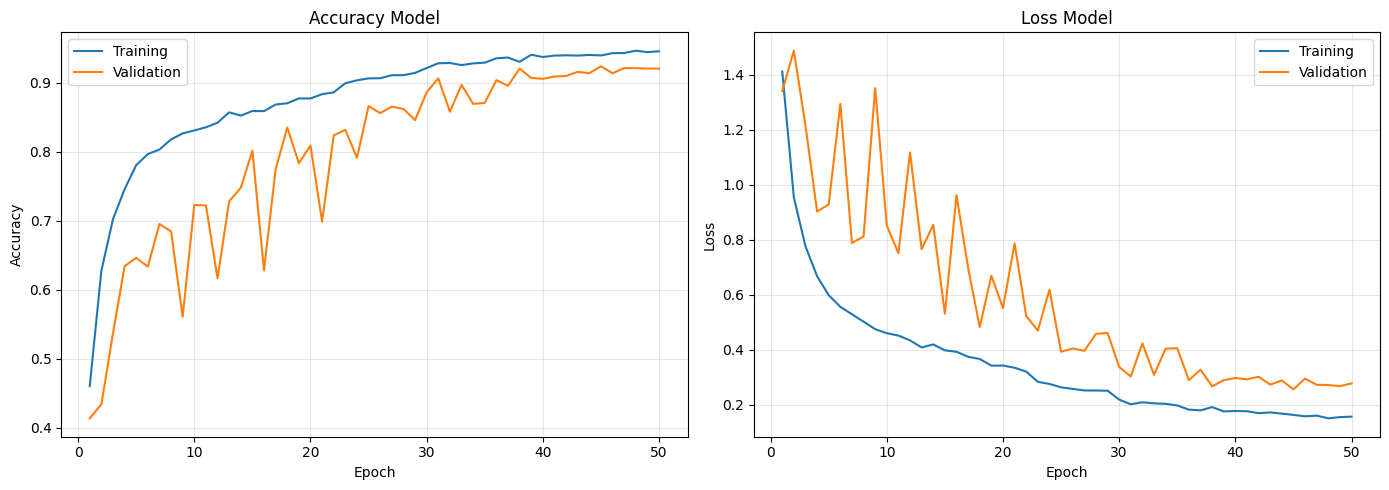

In [20]:
# ====================================
# Plot akurasi & loss selama training
# ====================================
acc      = history.history["accuracy"]
val_acc  = history.history["val_accuracy"]
loss     = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)

plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label="Training")
plt.plot(epochs_range, val_acc, label="Validation")
plt.title("Accuracy Model"); plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label="Training")
plt.plot(epochs_range, val_loss, label="Validation")
plt.title("Loss Model"); plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

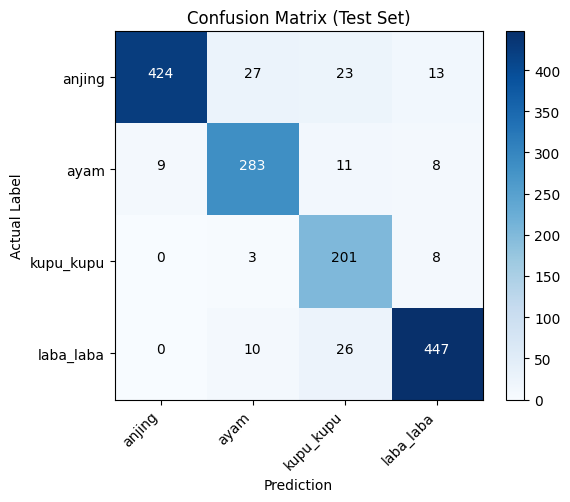

              precision    recall  f1-score   support

      anjing       0.98      0.87      0.92       487
        ayam       0.88      0.91      0.89       311
   kupu_kupu       0.77      0.95      0.85       212
   laba_laba       0.94      0.93      0.93       483

    accuracy                           0.91      1493
   macro avg       0.89      0.91      0.90      1493
weighted avg       0.92      0.91      0.91      1493



In [21]:
# ========================================
# Confusion matrix & classification report
# ========================================
y_true, y_pred = [], []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Confusion Matrix (Test Set)")
plt.colorbar()
plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)
for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, cm[i, j], ha="center",
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.ylabel("Actual Label"); plt.xlabel("Prediction")
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

## Konversi Model

In [22]:
# ===================================
# Konversi & simpan model ke 3 format
# ===================================

import os
import sys
import shutil
import subprocess
import importlib.util
import tensorflow as tf

from pathlib import Path
from google.colab import drive
drive.mount('/content/drive')

# ---- Konfigurasi ----
SUBMISSION_DIR = "/content/drive/MyDrive/submission"
SAVED_MODEL_DIR = os.path.join(SUBMISSION_DIR, "saved_model")
TFLITE_DIR      = os.path.join(SUBMISSION_DIR, "tflite")
TFJS_DIR        = os.path.join(SUBMISSION_DIR, "tfjs_model")

TFJS_SHARD_SIZE_BYTES = 1024 * 1024 * 1024

def bersihkan_direktori(path) -> None:
    path = Path(path)
    if path.exists():
        shutil.rmtree(path)

def pastikan_dependensi() -> None:
    for paket_pip, nama_modul in [("tensorflowjs", "tensorflowjs"),
                                  ("tf-keras", "tf_keras")]:
        if importlib.util.find_spec(nama_modul) is None:
            print(f"[Setup] Memasang {paket_pip} ...")
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", paket_pip],
                           check=True)

def ekspor_saved_model(keras_model, output_dir) -> None:
    output_dir = Path(output_dir)
    bersihkan_direktori(output_dir)
    keras_model.export(str(output_dir))

def ekspor_tflite(saved_model_dir, output_dir, labels: list) -> None:
    saved_model_dir, output_dir = Path(saved_model_dir), Path(output_dir)
    bersihkan_direktori(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    converter = tf.lite.TFLiteConverter.from_saved_model(str(saved_model_dir))
    converter.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_model = converter.convert()

    (output_dir / "model.tflite").write_bytes(tflite_model)
    (output_dir / "label.txt").write_text("\n".join(labels), encoding="utf-8")

def ekspor_tfjs(saved_model_dir, output_dir) -> None:
    saved_model_dir, output_dir = Path(saved_model_dir), Path(output_dir)
    bersihkan_direktori(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    env = os.environ.copy()
    env["TF_USE_LEGACY_KERAS"] = "1"
    env["CUDA_VISIBLE_DEVICES"] = "-1"

    perintah = [
        sys.executable, "-m", "tensorflowjs.converters.converter",
        "--input_format=tf_saved_model",
        "--output_format=tfjs_graph_model",
        f"--weight_shard_size_bytes={TFJS_SHARD_SIZE_BYTES}",
        str(saved_model_dir.resolve()),
        str(output_dir.resolve()),
    ]

    hasil = subprocess.run(perintah, env=env, capture_output=True, text=True)
    if hasil.returncode != 0:
        raise RuntimeError(
            f"--- STDOUT ---\n{hasil.stdout}\n"
            f"--- STDERR ---\n{hasil.stderr}"
        )

def verifikasi_struktur(base_dir) -> None:
    base_dir = Path(base_dir)
    berkas_wajib = [
        Path(SAVED_MODEL_DIR) / "saved_model.pb",
        Path(SAVED_MODEL_DIR) / "variables",
        Path(TFLITE_DIR) / "model.tflite",
        Path(TFLITE_DIR) / "label.txt",
        Path(TFJS_DIR) / "model.json",
    ]
    hilang = [p for p in berkas_wajib if not p.exists()]

    shard_bin = list(Path(TFJS_DIR).glob("*.bin")) if Path(TFJS_DIR).exists() else []
    if not shard_bin:
        hilang.append(Path(TFJS_DIR) / "group1-shard1of1.bin")

    if hilang:
        raise FileNotFoundError(
            "Berkas berikut hilang:\n" + "\n".join(f" - {p}" for p in hilang)
        )

    print("Seluruh berkas wajib berhasil dibuat.\n")
    print("Struktur direktori submission:")
    for root, _, files in os.walk(base_dir):
        level = Path(root).relative_to(base_dir).parts
        print("  " * len(level) + Path(root).name + "/")
        for berkas in sorted(files):
            print("  " * (len(level) + 1) + berkas)

# ---- Orkestrasi ----
if 'model' not in locals() and 'model' not in globals():
    print("Error: Variabel 'model' tidak ditemukan. Pastikan cell training sudah dijalankan.")
else:
    SUBMISSION_DIR = Path(SUBMISSION_DIR)
    SUBMISSION_DIR.mkdir(parents=True, exist_ok=True)
    pastikan_dependensi()

    ekspor_saved_model(model, SAVED_MODEL_DIR)
    print("SavedModel :", sorted(os.listdir(SAVED_MODEL_DIR)))

    ekspor_tflite(SAVED_MODEL_DIR, TFLITE_DIR, class_names)
    print("TF-Lite :", sorted(os.listdir(TFLITE_DIR)))

    ekspor_tfjs(SAVED_MODEL_DIR, TFJS_DIR)
    print("TF.js :", sorted(os.listdir(TFJS_DIR)))

    print()
    verifikasi_struktur(SUBMISSION_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[Setup] Memasang tensorflowjs ...
Saved artifact at '/content/drive/MyDrive/submission/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='keras_tensor_5')
Output Type:
  TensorSpec(shape=(None, 4), dtype=tf.float32, name=None)
Captures:
  138893116372560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138893116374864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138893116373520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138893116374288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138893116374096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138893116374480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138893116372752: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138891984093456: TensorSpec(sh

## Inference

Found 1493 files belonging to 4 classes.


/usr/local/lib/python3.12/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


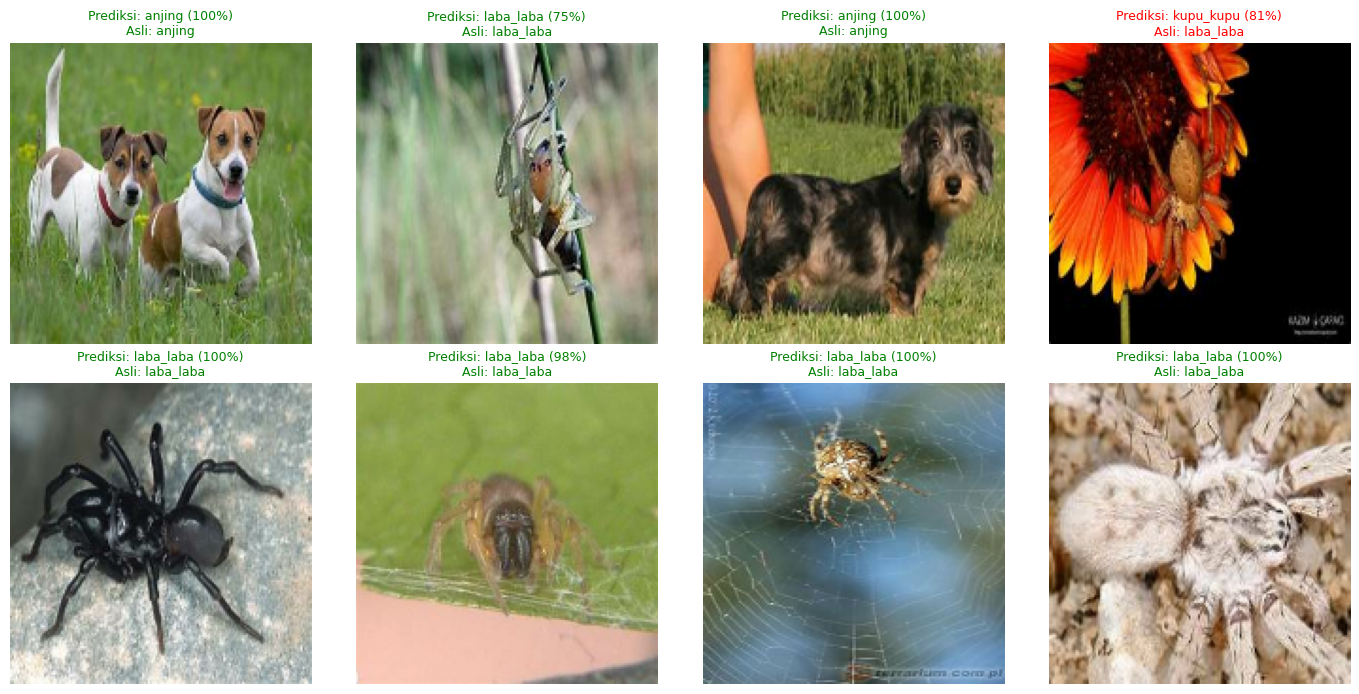

In [25]:
# ===================================
# Inferensi menggunakan model TF-Lite
# ===================================

with open(os.path.join(TFLITE_DIR, "label.txt")) as f:
    label_infer = [l.strip() for l in f.readlines() if l.strip()]

# Load interpreter TF-Lite
interpreter = tf.lite.Interpreter(model_path=os.path.join(TFLITE_DIR, "model.tflite"))
interpreter.allocate_tensors()
input_detail  = interpreter.get_input_details()[0]
output_detail = interpreter.get_output_details()[0]

def prediksi_tflite(citra):
    x = tf.expand_dims(citra, 0)
    x = tf.cast(x, input_detail["dtype"]).numpy()
    interpreter.set_tensor(input_detail["index"], x)
    interpreter.invoke()
    keluaran = interpreter.get_tensor(output_detail["index"])[0]
    return label_infer[int(np.argmax(keluaran))], float(np.max(keluaran))

# Ambil beberapa gambar dari test set
bukti_ds = muat_dataset("test", acak=True).take(1)
plt.figure(figsize=(14, 7))
for images, labels in bukti_ds:
    for i in range(min(8, images.shape[0])):
        pred_label, conf = prediksi_tflite(images[i])
        asli = class_names[int(labels[i])]
        ax = plt.subplot(2, 4, i + 1)
        ax.imshow(images[i].numpy().astype("uint8"))
        warna = "green" if pred_label == asli else "red"
        ax.set_title(f"Prediksi: {pred_label} ({conf:.0%})\nAsli: {asli}",
                     color=warna, fontsize=9)
        ax.axis("off")
    break
plt.tight_layout()
plt.show()

## Save requirements.txt

In [1]:
# ========================
# Membuat requirements.txt
# ========================
!pip freeze > requirements.txt
print("requirements.txt berhasil dibuat.")

requirements.txt berhasil dibuat.


In [15]:
!jupyter nbconvert --to markdown Notebook_DL.ipynb

[NbConvertApp] Converting notebook Notebook_DL.ipynb to markdown
[NbConvertApp] Support files will be in Notebook_DL_files/
[NbConvertApp] Making directory Notebook_DL_files
[NbConvertApp] Writing 62323 bytes to Notebook_DL.md
